# LM17 Lab — Law of Large Numbers and Central Limit Theorem

Companion notebook to **From Calculus to Kelly, LM17**. It rebuilds the module's exhibits and computational examples from the closes of the TAIEX total-return index, computes the widget's grid, solves the computational practice problems, and ends with an extension exercise.

| Part | Rebuilds |
|:--|:--|
| 1 | Data: TR23's returns, the exact check that no day is unchanged, $T$, years, $A$ and the guard |
| 2 | Averages: the two-trade table and Example 1 |
| 3 | The law of large numbers: coin probabilities against Chebyshev, Exhibit 2, the running mean log return |
| 4 | Mean path and median path: Exhibit 1, Example 3 with fractions (Exhibit 3), Example 4 |
| 5 | Leverage: the grid of $\bar g(f)$, $f^*$ and zero growth by `brentq`, Exhibit 4, Example 5 |
| 6 | The central limit theorem: Exhibit 5, Example 6, Example 7 and the 60-heads check |
| 7 | Lognormal wealth: Exhibit 6 and the model's exact law by FFT, the calendar years, the 2003–2025 refit (Example 8) and the widget's grid |
| 8 | How fast the normal arrives: Exhibit 7 with both window types, the lag correlations (Example 9) |
| 9 | When the laws fail: Exhibit 9 and Example 10 |
| 10 | Practice problems 6, 7, 8 and 11, and an extension: Exhibit 7 by limit regime |

**Environment.** From the repository root, `uv sync` installs the locked Python environment (`uv.lock`). Open this notebook with the `.venv` kernel, or run `uv run --with jupyterlab jupyter lab`.

**Data.** The notebook reads FinMind files that you download once with your own token. From the repository root, run `uv run python data/fetch_finmind.py`, then `uv run python data/make_lab_data.py`. FinMind's licence does not allow the book to redistribute the data. After that, the notebook runs offline.

`data/` then holds `taiex_tr.csv`: `date` and `price`, the daily closes of the TAIEX total-return index (FinMind `TaiwanStockTotalReturnIndex`, data_id TAIEX) from 2 January 2003 to 8 October 2026. The notebook reads nothing outside `data/`.

**Conventions (as in the module).** TR23 is the total-return index: $T=5{,}849$ simple daily returns $R_t$ from 3 January 2003; log returns $r_t=\ln(1+R_t)$ enter every sum; moments, correlations and kurtosis divide by the number of terms (`ddof=0`, `stats.kurtosis` defaults); years are calendar days / 365.25 and $A=T/\text{years}$; a horizon of $\tau$ years is $m=\operatorname{round}(A\tau)$ sessions. An up day is `R > 1e-12`. The iid model draws days from TR23's own returns: in-sample, a model, not a forecast. Leveraged paths are hypothetical (daily rebalancing, free borrowing, no costs). Nothing here is simulated.

In [1]:
from fractions import Fraction
from math import comb, exp, log, sqrt
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from scipy import optimize, stats

DATA = Path("data")
EPS = 1e-12
pl.Config.set_tbl_rows(30)
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})


def show(label, value, fmt, printed):
    # print a value next to the module's printed value and assert that they agree
    got = format(value, fmt)
    print(f"{label}: {got}   [book: {printed}]")
    assert got == printed, (label, got, printed)

## Part 1 — Data

Returns between consecutive closes, in Polars; then NumPy arrays for the arithmetic. The closes have two decimals, so an exact `Fraction` recount decides whether any day is unchanged, and the guard `R > 1e-12` must agree with it.

In [2]:
raw = pl.read_csv(DATA / "taiex_tr.csv", schema_overrides={"price": pl.String}).sort("date")
df = raw.with_columns(pl.col("price").cast(pl.Float64).alias("tr"))
df = df.with_columns((pl.col("tr") / pl.col("tr").shift(1) - 1).alias("R"))
dates_all = df["date"].to_list()
tr = df["tr"].to_numpy()
R = df["R"].to_numpy()[1:]
dates = dates_all[1:]
T = len(R)
r = np.log1p(R)
d0, d1 = (pl.Series([dates_all[0], dates_all[-1]]).str.to_date()).to_list()
years = (d1 - d0).days / 365.25
A = T / years
print(f"{len(tr)} closes {dates_all[0]} .. {dates_all[-1]}; first return {dates[0]}")
show("T", T, ",", "5,849")
show("calendar days from the first close", (d1 - d0).days, ",", "8,680")
show("years", years, ".4f", "23.7645")
show("A", A, ".2f", "246.12")

# exact signs from the two-decimal closes (as strings, so no float rounding enters)
closes = [Fraction(p) for p in raw["price"].to_list()]
ret_exact = [closes[i] / closes[i - 1] - 1 for i in range(1, len(closes))]
up_x = sum(x > 0 for x in ret_exact)
dn_x = sum(x < 0 for x in ret_exact)
zero_x = sum(x == 0 for x in ret_exact)
print(f"exact: {up_x} up, {dn_x} down, {zero_x} unchanged; guard R > 1e-12 counts {int((R > EPS).sum())} up days")
assert int((R > EPS).sum()) == up_x and int((R < -EPS).sum()) == dn_x
show("up days", up_x, ",", "3,205")
show("down days", dn_x, ",", "2,644")
Rb, rb, sr = R.mean(), r.mean(), r.std()
show("mean daily return (%)", 100 * Rb, ".6f", "0.062505")
show("mean daily log return (%)", 100 * rb, ".6f", "0.055170")
show("s_r (%), divisor T", 100 * sr, ".4f", "1.2107")

5850 closes 2003-01-02 .. 2026-10-08; first return 2003-01-03
T: 5,849   [book: 5,849]
calendar days from the first close: 8,680   [book: 8,680]
years: 23.7645   [book: 23.7645]
A: 246.12   [book: 246.12]
exact: 3205 up, 2644 down, 0 unchanged; guard R > 1e-12 counts 3205 up days
up days: 3,205   [book: 3,205]
down days: 2,644   [book: 2,644]
mean daily return (%): 0.062505   [book: 0.062505]
mean daily log return (%): 0.055170   [book: 0.055170]
s_r (%), divisor T: 1.2107   [book: 1.2107]


## Part 2 — Sums and averages

Two independent trades of LM3's +2%/−1% bet: the four equally likely averages, their mean and variance (divisor 4, in %²). Then Example 1: the standard error $1.5\%/\sqrt n$.

In [3]:
two = pl.DataFrame({"first": ["+", "+", "-", "-"], "second": ["+", "-", "+", "-"],
                    "average (%)": [2.0, 0.5, 0.5, -1.0]})
print(two)
avg = two["average (%)"].to_numpy()
show("mean of the average (%)", avg.mean(), ".1f", "0.5")
show("variance of the average (%^2)", avg.var(), ".3f", "1.125")
show("variance of one trade (%^2)", np.var([2.0, -1.0]), ".2f", "2.25")
for n, p in ((100, "0.15"), (10_000, "0.015")):
    show(f"Example 1 standard error after {n:,} trades (%)", 1.5 / sqrt(n), ".2f" if n == 100 else ".3f", p)
n_min = next(n for n in range(1, 1000) if 1.5 / sqrt(n) <= 0.25 + 1e-12)
show("smallest n with a standard error <= 0.25%", n_min, "d", "36")

shape: (4, 3)
┌───────┬────────┬─────────────┐
│ first ┆ second ┆ average (%) │
│ ---   ┆ ---    ┆ ---         │
│ str   ┆ str    ┆ f64         │
╞═══════╪════════╪═════════════╡
│ +     ┆ +      ┆ 2.0         │
│ +     ┆ -      ┆ 0.5         │
│ -     ┆ +      ┆ 0.5         │
│ -     ┆ -      ┆ -1.0        │
└───────┴────────┴─────────────┘
mean of the average (%): 0.5   [book: 0.5]
variance of the average (%^2): 1.125   [book: 1.125]
variance of one trade (%^2): 2.25   [book: 2.25]
Example 1 standard error after 100 trades (%): 0.15   [book: 0.15]
Example 1 standard error after 10,000 trades (%): 0.015   [book: 0.015]
smallest n with a standard error <= 0.25%: 36   [book: 36]


## Part 3 — The law of large numbers

Exact coin probabilities $\Pr(\lvert j/n-\tfrac12\rvert\ge0.1)$ against Chebyshev's $25/n$ (the comparison $\lvert 10j-5n\rvert\ge n$ is done in integers, so no float sits on the edge), then Exhibit 2 and the running annualized mean log return.

shape: (3, 3)
┌──────┬────────────┬────────────────┐
│ n    ┆ exact      ┆ Chebyshev 25/n │
│ ---  ┆ ---        ┆ ---            │
│ i64  ┆ f64        ┆ f64            │
╞══════╪════════════╪════════════════╡
│ 10   ┆ 0.753906   ┆ 2.5            │
│ 100  ┆ 0.056888   ┆ 0.25           │
│ 1000 ┆ 2.7285e-10 ┆ 0.025          │
└──────┴────────────┴────────────────┘
exact, n = 10: 0.7539   [book: 0.7539]
exact, n = 100: 0.05689   [book: 0.05689]
exact, n = 1,000: 2.7e-10   [book: 2.7e-10]
Example 2: 50,000   [book: 50,000]
running up share after 246: 0.5163   [book: 0.5163]
running up share after 1,231: 0.5378   [book: 0.5378]
whole-sample share: 0.5480   [book: 0.5480]
band half-width at T: 0.0130   [book: 0.0130]


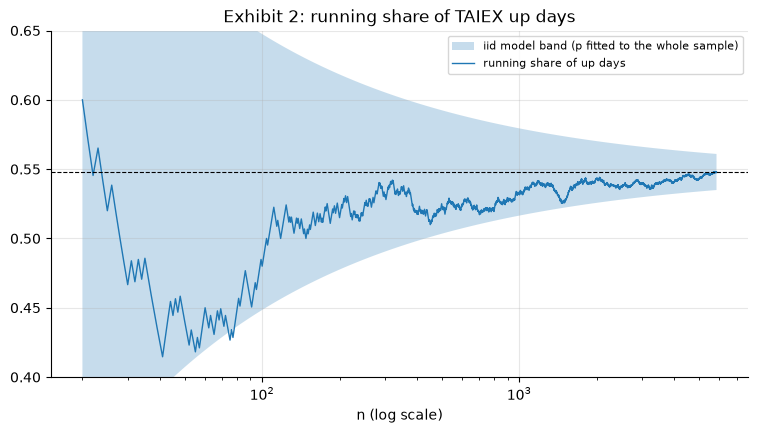

running A * mean log return: 27.12% after 246 days, low 2.03% on 2008-11-20, 13.58% at the end (LM14's 13.58%)
A * mean log return at the end (%): 13.58   [book: 13.58]


In [4]:
def coin_tail(n):
    return float(Fraction(sum(comb(n, j) for j in range(n + 1) if abs(10 * j - 5 * n) >= n), 2**n))


print(pl.DataFrame({"n": [10, 100, 1000], "exact": [coin_tail(n) for n in (10, 100, 1000)],
                    "Chebyshev 25/n": [25 / n for n in (10, 100, 1000)]}))
show("exact, n = 10", coin_tail(10), ".4f", "0.7539")
show("exact, n = 100", coin_tail(100), ".5f", "0.05689")
show("exact, n = 1,000", coin_tail(1000), ".1e", "2.7e-10")
show("Example 2", 0.25 / (0.01**2 * 0.05), ",.0f", "50,000")

n_ = np.arange(1, T + 1)
up_share = np.cumsum(R > EPS) / n_
p_hat = up_share[-1]
show("running up share after 246", up_share[245], ".4f", "0.5163")
show("running up share after 1,231", up_share[1230], ".4f", "0.5378")
show("whole-sample share", p_hat, ".4f", "0.5480")
show("band half-width at T", 2 * sqrt(p_hat * (1 - p_hat) / T), ".4f", "0.0130")
ns = np.arange(20, T + 1)
half = 2 * np.sqrt(p_hat * (1 - p_hat) / ns)
fig, ax = plt.subplots()
ax.fill_between(ns, p_hat - half, p_hat + half, alpha=0.25, label="iid model band (p fitted to the whole sample)")
ax.plot(ns, up_share[19:], lw=1, label="running share of up days")
ax.axhline(p_hat, ls="--", lw=0.8, color="black")
ax.set_xscale("log"); ax.set_ylim(0.40, 0.65); ax.set_xlabel("n (log scale)")
ax.set_title("Exhibit 2: running share of TAIEX up days"); ax.legend(fontsize=8); plt.show()

# lab-only figures (the module does not print them): the running annualized mean log return
run_g = A * np.cumsum(r) / n_
low = 245 + int(run_g[245:].argmin())
print(f"running A * mean log return: {run_g[245]:.2%} after 246 days, low {run_g[low]:.2%} on {dates[low]}, "
      f"{run_g[-1]:.2%} at the end (LM14's 13.58%)")
show("A * mean log return at the end (%)", 100 * run_g[-1], ".2f", "13.58")

## Part 4 — The mean path and the median path

Exhibit 1 on a log scale, then Example 3 in exact fractions (Exhibit 3), then Example 4.

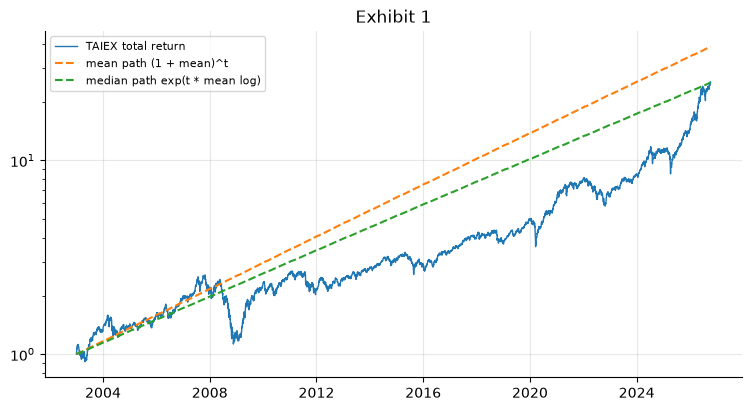

realized wealth: 25.20   [book: 25.20]
mean path: 38.66   [book: 38.66]
median path (by construction): 25.20   [book: 25.20]
shape: (11, 5)
┌─────┬────────┬───────┬─────────────┬──────────────┐
│ j   ┆ W10/W0 ┆ paths ┆ probability ┆ contribution │
│ --- ┆ ---    ┆ ---   ┆ ---         ┆ ---          │
│ i64 ┆ str    ┆ i64   ┆ f64         ┆ f64          │
╞═════╪════════╪═══════╪═════════════╪══════════════╡
│ 0   ┆ 1/1024 ┆ 1     ┆ 0.000977    ┆ 9.5367e-7    │
│ 1   ┆ 1/256  ┆ 10    ┆ 0.009766    ┆ 0.000038     │
│ 2   ┆ 1/64   ┆ 45    ┆ 0.043945    ┆ 0.000687     │
│ 3   ┆ 1/16   ┆ 120   ┆ 0.1171875   ┆ 0.007324     │
│ 4   ┆ 1/4    ┆ 210   ┆ 0.205078    ┆ 0.05127      │
│ 5   ┆ 1      ┆ 252   ┆ 0.246094    ┆ 0.246094     │
│ 6   ┆ 4      ┆ 210   ┆ 0.205078    ┆ 0.8203125    │
│ 7   ┆ 16     ┆ 120   ┆ 0.1171875   ┆ 1.875        │
│ 8   ┆ 64     ┆ 45    ┆ 0.043945    ┆ 2.8125       │
│ 9   ┆ 256    ┆ 10    ┆ 0.009766    ┆ 2.5          │
│ 10  ┆ 1024   ┆ 1     ┆ 0.000977    ┆ 1.0        

In [5]:
t = np.arange(len(tr))
W = tr / tr[0]
fig, ax = plt.subplots()
ax.semilogy(pl.Series(dates_all).str.to_date().to_list(), W, lw=1, label="TAIEX total return")
ax.semilogy(pl.Series(dates_all).str.to_date().to_list(), (1 + Rb) ** t, "--", label="mean path (1 + mean)^t")
ax.semilogy(pl.Series(dates_all).str.to_date().to_list(), np.exp(t * rb), "--", label="median path exp(t * mean log)")
ax.set_title("Exhibit 1"); ax.legend(fontsize=8); plt.show()
show("realized wealth", W[-1], ".2f", "25.20")
show("mean path", (1 + Rb) ** T, ".2f", "38.66")
show("median path (by construction)", exp(T * rb), ".2f", "25.20")

ew10 = Fraction(5, 4) ** 10
rows = []
for j in range(11):
    p = Fraction(comb(10, j), 1024)
    w = Fraction(2) ** (2 * j - 10)
    rows.append({"j": j, "W10/W0": str(w), "paths": comb(10, j), "probability": float(p), "contribution": float(p * w)})
tbl = pl.DataFrame(rows)
print(tbl)   # Exhibit 3
assert sum(Fraction(comb(10, j), 1024) * Fraction(2) ** (2 * j - 10) for j in range(11)) == ew10
show("Example 3 E W10", float(ew10), ".4f", "9.3132")
above = sum(Fraction(comb(10, j), 1024) for j in range(7, 11))
print("Pr(W10 > E W10) =", above, "; Pr(W10 < W0) =", sum(Fraction(comb(10, j), 1024) for j in range(5)))
show("share of the mean from j >= 7 (%)", float(100 * sum(Fraction(comb(10, j), 1024) * Fraction(2) ** (2 * j - 10)
                                                         for j in range(7, 11)) / ew10), ".1f", "87.9")
j100 = next(j for j in range(101) if Fraction(2) ** (2 * j - 100) > Fraction(5, 4) ** 100)
print(f"100 rounds: E W100 = {1.25**100:.2e}; wealth beats it from j = {j100} wins")
show("100 rounds: Pr(W100 > E W100)", float(Fraction(sum(comb(100, j) for j in range(j100, 101)), 2**100)), ".5f", "0.00044")
show("100 rounds: Pr(W100 < W0)", float(Fraction(sum(comb(100, j) for j in range(50)), 2**100)), ".4f", "0.4602")

delta = log(1 + Rb) - rb
show("Example 4 daily Jensen gap (bp)", 1e4 * delta, ".4f", "0.7316")
show("factor exp(T delta)", exp(T * delta), ".3f", "1.534")
z = sqrt(T) * delta / sr
show("z", z, ".3f", "0.462")
show("Pr(W_T > E W_T), normal approximation", stats.norm.sf(z), ".2f", "0.32")
show("Chebyshev's bound", sr**2 / (T * delta**2), ".2f", "4.68")
print(f"days for a 5% chance: {(stats.norm.ppf(0.95) * sr / delta) ** 2:,.0f}")

## Part 5 — Leverage

$\bar g(f)$ of (4.4) on a grid, the Kelly leverage $f^*$ as the root of (4.5) and the zero-growth leverage by `brentq`, then Exhibit 4 and the table of Example 5. The domain ends at $1/\lvert R_{(1)}\rvert$, where the worst day wipes the position out.

domain edge 1/|R_(1)|: 10.31   [book: 10.31]
f*: 4.1381   [book: 4.1381]
A gbar(f*) (%): 32.28   [book: 32.28]
wealth at f*: 2,147   [book: 2,147]
zero growth: 8.04   [book: 8.04]
shape: (5, 4)
┌─────┬─────────────┬──────────┬─────────────┐
│ f   ┆ W_T         ┆ A gbar   ┆ mean path   │
│ --- ┆ ---         ┆ ---      ┆ ---         │
│ i64 ┆ f64         ┆ f64      ┆ f64         │
╞═════╪═════════════╪══════════╪═════════════╡
│ 1   ┆ 25.200684   ┆ 0.135785 ┆ 38.658976   │
│ 2   ┆ 267.727403  ┆ 0.235223 ┆ 1491.109435 │
│ 4   ┆ 2127.846744 ┆ 0.32245  ┆ 2.2032e6    │
│ 6   ┆ 405.588639  ┆ 0.252702 ┆ 3.2260e9    │
│ 8   ┆ 1.17536     ┆ 0.006799 ┆ 4.6808e12   │
└─────┴─────────────┴──────────┴─────────────┘
W_T at f = 4: 2,127.8   [book: 2,127.8]
A gbar at f = 4 (%): 32.24   [book: 32.24]
Pr(W > EW) at f*, normal approximation: 0.028   [book: 0.028]
largest drawdown at f* (%): 98.5   [book: 98.5]
trough on 2008-11-20


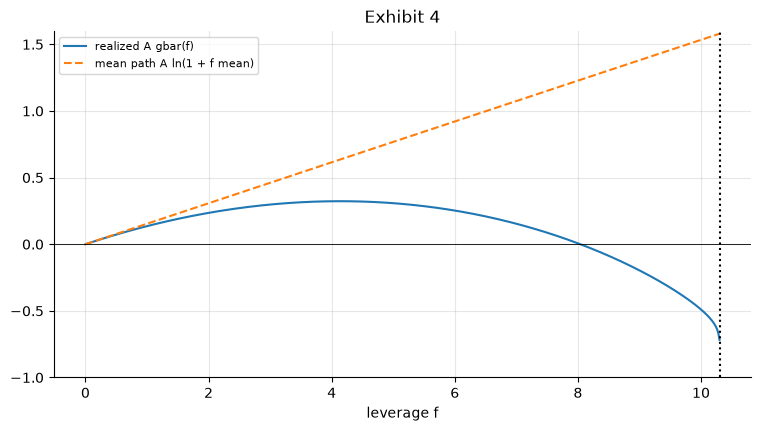

In [6]:
def gbar(f):
    return np.log1p(f * R).mean()


def sdl(f):
    return np.log1p(f * R).std()


fmax = 1 / abs(R.min())
fstar = optimize.brentq(lambda f: (R / (1 + f * R)).mean(), 0.0, fmax - 1e-6)
fzero = optimize.brentq(gbar, fstar, fmax - 1e-9)
show("domain edge 1/|R_(1)|", fmax, ".2f", "10.31")
show("f*", fstar, ".4f", "4.1381")
show("A gbar(f*) (%)", 100 * A * gbar(fstar), ".2f", "32.28")
show("wealth at f*", exp(T * gbar(fstar)), ",.0f", "2,147")
show("zero growth", fzero, ".2f", "8.04")
fl = [1, 2, 4, 6, 8]
lev = pl.DataFrame({"f": fl, "W_T": [exp(T * gbar(f)) for f in fl], "A gbar": [A * gbar(f) for f in fl],
                    "mean path": [(1 + f * Rb) ** T for f in fl]})
print(lev)   # Example 5
show("W_T at f = 4", lev["W_T"][2], ",.1f", "2,127.8")
show("A gbar at f = 4 (%)", 100 * lev["A gbar"][2], ".2f", "32.24")
d_star = log(1 + fstar * Rb) - gbar(fstar)
show("Pr(W > EW) at f*, normal approximation", stats.norm.sf(sqrt(T) * d_star / sdl(fstar)), ".3f", "0.028")
wl = np.concatenate([[1.0], np.exp(np.cumsum(np.log1p(fstar * R)))])
dd = 1 - wl / np.maximum.accumulate(wl)
show("largest drawdown at f* (%)", 100 * dd.max(), ".1f", "98.5")
print("trough on", dates_all[int(dd.argmax())])
fs = np.linspace(0, 10.30, 516)
fig, ax = plt.subplots()
ax.plot(fs, [A * gbar(f) for f in fs], label="realized A gbar(f)")
ax.plot(fs, A * np.log1p(fs * Rb), "--", label="mean path A ln(1 + f mean)")
ax.axvline(fmax, ls=":", color="black"); ax.axhline(0, color="black", lw=0.6)
ax.set_ylim(-1, 1.6); ax.set_xlabel("leverage f"); ax.set_title("Exhibit 4"); ax.legend(fontsize=8); plt.show()

## Part 6 — The central limit theorem

Exhibit 5, then Example 6 at $n=100$ and $n=10$, Example 7 and the knowledge check on 60 heads.

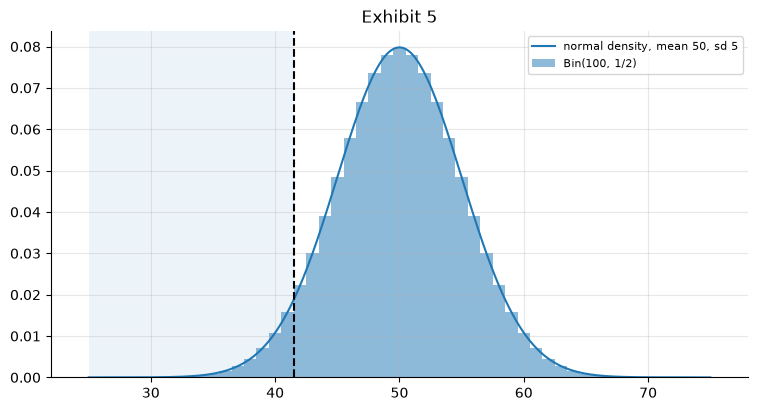

losing counts at n = 100: j <= 41
Example 6 exact: 0.04431   [book: 0.04431]
z: -1.69925   [book: -1.69925]
normal: 0.04464   [book: 0.04464]
corrected: 0.04457   [book: 0.04457]
n = 10 exact: 0.37695   [book: 0.37695]
n = 10 normal: 0.29551   [book: 0.29551]
n = 10 corrected: 0.37591   [book: 0.37591]
Example 7: 9,604   [book: 9,604]
60 heads or more, exact (%): 2.84   [book: 2.84]
60 heads or more, corrected (%): 2.87   [book: 2.87]


In [7]:
gs = 0.5 * log(1.5) + 0.5 * log(0.75)
sg = log(2) / 2
thr = log(4 / 3) / log(2)


def coin(n):
    jmax = int(np.ceil(thr * n)) - 1
    z = -gs * sqrt(n) / sg
    return jmax, stats.binom.cdf(jmax, n, 0.5), stats.norm.cdf(z), stats.norm.cdf((jmax + 0.5 - n / 2) / (sqrt(n) / 2)), z


js = np.arange(25, 76)
xs = np.linspace(25, 75, 401)
fig, ax = plt.subplots()
ax.bar(js, stats.binom.pmf(js, 100, 0.5), width=1, alpha=0.5, label="Bin(100, 1/2)")
ax.plot(xs, stats.norm.pdf((xs - 50) / 5) / 5, label="normal density, mean 50, sd 5")
ax.axvline(41.5, ls="--", color="black"); ax.axvspan(25, 41.5, alpha=0.08)
ax.set_title("Exhibit 5"); ax.legend(fontsize=8); plt.show()
jmax, ex100, nm100, cc100, z100 = coin(100)
print("losing counts at n = 100: j <=", jmax)
show("Example 6 exact", ex100, ".5f", "0.04431")
show("z", z100, ".5f", "-1.69925")
show("normal", nm100, ".5f", "0.04464")
show("corrected", cc100, ".5f", "0.04457")
_, ex10, nm10, cc10, _ = coin(10)
show("n = 10 exact", ex10, ".5f", "0.37695")
show("n = 10 normal", nm10, ".5f", "0.29551")
show("n = 10 corrected", cc10, ".5f", "0.37591")
show("Example 7", 1.96**2 * 0.25 / 0.01**2, ",.0f", "9,604")
show("60 heads or more, exact (%)", 100 * stats.binom.sf(59, 100, 0.5), ".2f", "2.84")
show("60 heads or more, corrected (%)", 100 * stats.norm.sf((59.5 - 50) / 5), ".2f", "2.87")

## Part 7 — Lognormal wealth

Exhibit 6 from (17.6), the normal approximation; then the model's exact law of the sum, the calendar years 2003–2025 (2003 from its first close, exact arithmetic on the closes), the daily model refitted to them (Example 8) and the widget's grid of $(f,\bar g(f),s_r(f))$.

The exact law needs no approximation: the sum of $m$ independent draws from TR23's empirical law has the $m$-th power of one draw's Fourier transform. Place each centred log return on a lattice of step $10^{-5}$ (its mass split between the two neighbouring points, which keeps the mean), raise the FFT to the power $m$ and transform back. From that law come every column of Exhibit 6 but the mean path, and the largest gaps from (17.6) that its note bounds by 0.2 points and 0.2%.

In [8]:
z95 = stats.norm.ppf(0.95)


def x6_row(m):
    return {"m": m, "median": exp(m * rb), "mean path": (1 + Rb) ** m, "5%": exp(m * rb - z95 * sr * sqrt(m)),
            "95%": exp(m * rb + z95 * sr * sqrt(m)), "Pr(W<W0)": stats.norm.cdf(-rb * sqrt(m) / sr),
            "Pr(W>EW)": stats.norm.sf(sqrt(m) * delta / sr)}


x6 = pl.DataFrame([x6_row(m) for m in (round(A), round(10 * A), T)])
print(x6)   # Exhibit 6
show("one year: loss (%)", 100 * x6["Pr(W<W0)"][0], ".2f", "23.74")
show("ten years: loss (%)", 100 * x6["Pr(W<W0)"][1], ".2f", "1.19")
show("sample: 5% quantile", x6["5%"][2], ".2f", "5.49")
show("sample: 95% quantile", x6["95%"][2], ".1f", "115.6")
show("sample: loss (%)", 100 * x6["Pr(W<W0)"][2], ".3f", "0.025")

# the model's exact law of the m-day sum, by FFT on a lattice of step H (the sum centred on m * mean)
H, NPT = 1e-5, 2**22


def lattice_ft(x):
    # Fourier transform of the empirical law of x - mean(x) on the lattice, each mass split between two neighbours
    y = (x - x.mean()) / H
    lo = np.floor(y).astype(np.int64)
    w_hi = y - lo
    pmf = (np.bincount(lo % NPT, weights=(1 - w_hi) / len(x), minlength=NPT)
           + np.bincount((lo + 1) % NPT, weights=w_hi / len(x), minlength=NPT))
    return np.fft.fft(pmf)


def exact_law(ft, m):
    # lattice pmf of the centred m-day sum (index NPT/2 is 0) and its cumulative sums
    pm = np.fft.fftshift(np.fft.ifft(ft**m).real)
    return pm, np.cumsum(pm)


def law_cdf(pm, cum, c):
    # Pr(centred sum < c), each lattice mass spread evenly over its cell
    k = c / H + NPT // 2
    j = int(np.floor(k + 0.5))
    return cum[j - 1] + (k - (j - 0.5)) * pm[j]


def law_quantile(pm, cum, u):
    # the c with Pr(centred sum < c) = u
    j = int(np.searchsorted(cum, u))
    return (j - 0.5 - NPT // 2 + (u - cum[j - 1]) / pm[j]) * H


ft_r = lattice_ft(r)
rows, gap_p, gap_q = [], [], []
for k, m in enumerate((round(A), round(10 * A), T)):
    pm, cum = exact_law(ft_r, m)
    q = [exp(m * rb + law_quantile(pm, cum, u)) for u in (0.05, 0.5, 0.95)]
    rows.append({"m": m, "median": q[1], "5%": q[0], "95%": q[2], "Pr(W<W0)": law_cdf(pm, cum, -m * rb),
                 "Pr(W>EW)": 1 - law_cdf(pm, cum, m * delta)})
    gap_p += [abs(x6[c][k] - rows[-1][c]) for c in ("Pr(W<W0)", "Pr(W>EW)")]
    gap_q += [abs(x6[c][k] / rows[-1][c] - 1) for c in ("5%", "median", "95%")]
exact6 = pl.DataFrame(rows)
print(exact6)   # the exact law, against (17.6) in the table above
print(f"largest gaps from (17.6): {100 * max(gap_p):.3f} points (probabilities), {100 * max(gap_q):.3f}% (quantiles)")
assert max(gap_p) < 0.002 and max(gap_q) < 0.002   # the note: at most 0.2 points and 0.2%
show("exact loss probability, one year (%)", 100 * exact6["Pr(W<W0)"][0], ".2f", "23.62")
show("exact loss probability, the sample (%)", 100 * exact6["Pr(W<W0)"][2], ".3f", "0.026")

yearly = (df.with_columns(pl.col("date").str.slice(0, 4).alias("year"))
            .group_by("year", maintain_order=True).agg(pl.col("price").last().alias("last")).sort("year"))
first_close = Fraction(raw["price"][0])
prev, losses, ann = first_close, [], []
for y, last in zip(yearly["year"].to_list(), yearly["last"].to_list()):
    if y > "2025":
        break
    g_y = Fraction(last) / prev
    ann.append(log(float(g_y)))
    if g_y < 1:
        losses.append(y)
    prev = Fraction(last)
print("losing calendar years:", losses)
show("losing years of 23", len(losses), "d", "5")
in_win = np.array([d <= "2025-12-31" for d in dates])   # ISO dates compare as strings
r_w = r[in_win]
p_w = stats.norm.cdf(-r_w.mean() * sqrt(246) / r_w.std())
show("returns 2003-2025", len(r_w), ",", "5,664")
show("refitted daily mean log return (%)", 100 * r_w.mean(), ".6f", "0.047292")
show("refitted daily standard deviation (%)", 100 * r_w.std(), ".5f", "1.18352")
show("246 x refitted mean (%)", 100 * 246 * r_w.mean(), ".3f", "11.634")
show("sqrt(246) x refitted standard deviation (%)", 100 * sqrt(246) * r_w.std(), ".3f", "18.563")
show("refitted daily model: losing-year chance by (17.6) (%)", 100 * p_w, ".2f", "26.54")
show("losing years of 23 by (17.6)", 23 * p_w, ".2f", "6.10")
pm, cum = exact_law(lattice_ft(r_w), 246)
p_w_exact = law_cdf(pm, cum, -246 * r_w.mean())
print(f"the refitted model's exact law: losing-year chance {p_w_exact:.2%}, {23 * p_w_exact:.2f} losing years of 23")
la = np.array(ann)
show("LM15's annual fit: Pr(G < 1) (%)", 100 * stats.norm.cdf(-la.mean() / la.std()), ".1f", "30.0")

fg = [0.25 * k for k in range(1, 33)]
grid = pl.DataFrame({"f": fg, "gbar": [gbar(f) for f in fg], "s_r": [sdl(f) for f in fg]})
print(grid.head(8))
show("widget: five-year loss at f = 1 (%)", 100 * stats.norm.cdf(-rb * sqrt(round(5 * A)) / sr), ".2f", "5.49")

shape: (3, 7)
┌──────┬───────────┬───────────┬──────────┬────────────┬──────────┬──────────┐
│ m    ┆ median    ┆ mean path ┆ 5%       ┆ 95%        ┆ Pr(W<W0) ┆ Pr(W>EW) │
│ ---  ┆ ---       ┆ ---       ┆ ---      ┆ ---        ┆ ---      ┆ ---      │
│ i64  ┆ f64       ┆ f64       ┆ f64      ┆ f64        ┆ f64      ┆ f64      │
╞══════╪═══════════╪═══════════╪══════════╪════════════╪══════════╪══════════╡
│ 246  ┆ 1.145358  ┆ 1.166158  ┆ 0.838088 ┆ 1.565283   ┆ 0.237398 ┆ 0.462247 │
│ 2461 ┆ 3.887337  ┆ 4.654195  ┆ 1.447427 ┆ 10.440175  ┆ 0.011894 ┆ 0.382179 │
│ 5849 ┆ 25.200684 ┆ 38.658976 ┆ 5.494903 ┆ 115.575204 ┆ 0.000246 ┆ 0.321994 │
└──────┴───────────┴───────────┴──────────┴────────────┴──────────┴──────────┘
one year: loss (%): 23.74   [book: 23.74]
ten years: loss (%): 1.19   [book: 1.19]
sample: 5% quantile: 5.49   [book: 5.49]
sample: 95% quantile: 115.6   [book: 115.6]
sample: loss (%): 0.025   [book: 0.025]
shape: (3, 6)
┌──────┬───────────┬──────────┬───────────┬──────────

## Part 8 — How fast the normal arrives

Exhibit 7: overlapping sums of $m$ daily log returns (all $T-m+1$ windows) and non-overlapping ones from every starting day, against $5.428/m$; then the lag correlations of Example 9.

shape: (6, 5)
┌─────┬─────────────┬─────────────┬───────────────────────────┬────────────────────────────────────┐
│ m   ┆ overlapping ┆ iid 5.428/m ┆ non-overlapping, min over ┆ non-overlapping, max over star…    │
│ --- ┆ ---         ┆ ---         ┆ star…                     ┆ ---                                │
│ i64 ┆ f64         ┆ f64         ┆ ---                       ┆ f64                                │
│     ┆             ┆             ┆ f64                       ┆                                    │
╞═════╪═════════════╪═════════════╪═══════════════════════════╪════════════════════════════════════╡
│ 1   ┆ 5.427759    ┆ 5.428       ┆ 5.427759                  ┆ 5.427759                           │
│ 2   ┆ 5.044959    ┆ 2.714       ┆ 4.307331                  ┆ 5.737575                           │
│ 5   ┆ 3.62979     ┆ 1.0856      ┆ 2.25025                   ┆ 4.548209                           │
│ 10  ┆ 3.022901    ┆ 0.5428      ┆ 0.961577                  ┆ 6.3043       

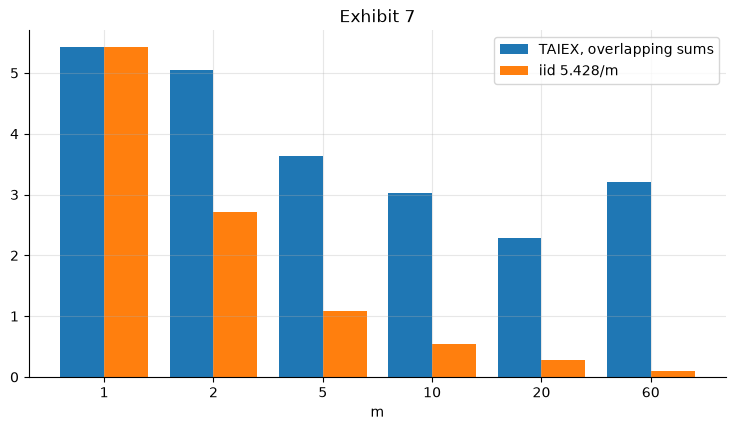

corr(r_t, r_t+1): 0.039   [book: 0.039]
corr(|r_t|, |r_t+1|): 0.161   [book: 0.161]
corr(|r_t|, |r_t+20|): 0.123   [book: 0.123]


In [9]:
def window_sums(x, m):
    c = np.concatenate([[0.0], np.cumsum(x)])
    return c[m:] - c[:-m]


def blocks(x, m, offset=0):
    k = (len(x) - offset) // m
    return x[offset: offset + k * m].reshape(k, m).sum(axis=1)


ms = [1, 2, 5, 10, 20, 60]
kt = pl.DataFrame({"m": ms,
                   "overlapping": [stats.kurtosis(window_sums(r, m)) for m in ms],
                   "iid 5.428/m": [5.428 / m for m in ms],
                   "non-overlapping, min over starts": [min(stats.kurtosis(blocks(r, m, o)) for o in range(m)) for m in ms],
                   "non-overlapping, max over starts": [max(stats.kurtosis(blocks(r, m, o)) for o in range(m)) for m in ms]})
print(kt)   # Exhibit 7
show("daily excess kurtosis of r", stats.kurtosis(r), ".3f", "5.428")
for m, p in zip(ms, ["5.43", "5.04", "3.63", "3.02", "2.29", "3.20"]):
    show(f"overlapping {m}-day sums", stats.kurtosis(window_sums(r, m)), ".2f", p)
show("20-day blocks from the first return", stats.kurtosis(blocks(r, 20)), ".2f", "2.40")
fig, ax = plt.subplots()
ax.bar(np.arange(6) - 0.2, kt["overlapping"], width=0.4, label="TAIEX, overlapping sums")
ax.bar(np.arange(6) + 0.2, kt["iid 5.428/m"], width=0.4, label="iid 5.428/m")
ax.set_xticks(range(6), [str(m) for m in ms]); ax.set_xlabel("m"); ax.set_title("Exhibit 7"); ax.legend(); plt.show()


def corr(a, b):
    # the correlation of the pairs (a_t, b_t), as LM16 defines it; LM26 treats the autocorrelation convention
    return np.corrcoef(a, b)[0, 1]


show("corr(r_t, r_t+1)", corr(r[:-1], r[1:]), ".3f", "0.039")
show("corr(|r_t|, |r_t+1|)", corr(np.abs(r[:-1]), np.abs(r[1:])), ".3f", "0.161")
show("corr(|r_t|, |r_t+20|)", corr(np.abs(r[:-20]), np.abs(r[20:])), ".3f", "0.123")

## Part 9 — When the laws fail

Exhibit 9: the running excess kurtosis of daily simple returns (divisor the days so far) against the running annualized variance, then Example 10.

running excess kurtosis through 2 April 2025: 4.25   [book: 4.25]
running excess kurtosis through 7 April 2025: 4.94   [book: 4.94]
full sample: 5.27   [book: 5.27]
running annualized variance from the 246th return: 0.0326 to 0.0580, end 0.0359
running annualized variance through 2 April 2025: 0.03335   [book: 0.03335]
running annualized variance through 7 April 2025: 0.03377   [book: 0.03377]
on 7 April 2025 the variance rose 1.3%, the excess kurtosis 16%


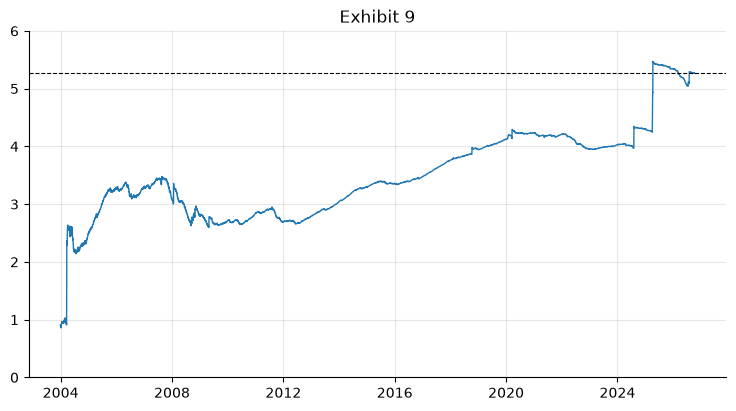

Example 10 normal average, n = 1: 0.317   [book: 0.317]
Example 10 normal average, n = 4: 0.0455   [book: 0.0455]
normal average, n = 25: 5.7e-07 ; Cauchy average, every n: 0.5


In [10]:
c1, c2, c3, c4 = (np.cumsum(R**k) for k in (1, 2, 3, 4))
mu = c1 / n_
m2 = c2 / n_ - mu**2
m4 = c4 / n_ - 4 * mu * c3 / n_ + 6 * mu**2 * c2 / n_ - 3 * mu**4
k_run = np.full(T, np.nan)
k_run[1:] = m4[1:] / m2[1:] ** 2 - 3
i2, i7 = dates.index("2025-04-02"), dates.index("2025-04-07")
show("running excess kurtosis through 2 April 2025", k_run[i2], ".2f", "4.25")
show("running excess kurtosis through 7 April 2025", k_run[i7], ".2f", "4.94")
show("full sample", k_run[-1], ".2f", "5.27")
var_a = A * m2   # running annualized variance of R: divisor the days so far, times A
print(f"running annualized variance from the 246th return: {var_a[245:].min():.4f} to {var_a[245:].max():.4f}, "
      f"end {var_a[-1]:.4f}")
show("running annualized variance through 2 April 2025", var_a[i2], ".5f", "0.03335")
show("running annualized variance through 7 April 2025", var_a[i7], ".5f", "0.03377")
print(f"on 7 April 2025 the variance rose {var_a[i7] / var_a[i2] - 1:.1%}, "
      f"the excess kurtosis {k_run[i7] / k_run[i2] - 1:.0%}")
fig, ax = plt.subplots()
d_list = pl.Series(dates).str.to_date().to_list()
ax.plot(d_list[245:], k_run[245:], lw=1)
ax.axhline(k_run[-1], ls="--", color="black", lw=0.8)
ax.set_ylim(0, 6); ax.set_title("Exhibit 9"); plt.show()

for n, p in ((1, "0.317"), (4, "0.0455")):
    show(f"Example 10 normal average, n = {n}", 2 * stats.norm.sf(sqrt(n)), ".3g", p)
print("normal average, n = 25:", f"{2 * stats.norm.sf(5):.1e}", "; Cauchy average, every n:",
      1 - 2 / np.pi * np.arctan(1.0))

## Part 10 — Practice problems

Problems 6, 7, 8 and 11. Problem 7 uses the printed inputs, as its stem says.

In [11]:
jmax, ex400, nm400, cc400, z400 = coin(400)
print("P6: losing counts j <=", jmax)
show("P6 exact", ex400, ".6f", "0.000394")
show("P6 z", z400, ".4f", "-3.3985")
show("P6 normal", nm400, ".6f", "0.000339")
show("P6 corrected", cc400, ".6f", "0.000404")
print(f"P6 uncorrected relative errors: n = 400 {nm400 / ex400 - 1:+.2%}, n = 100 {nm100 / ex100 - 1:+.2%}")
print(f"P6 corrected relative errors: n = 400 {cc400 / ex400 - 1:+.2%}, n = 100 {cc100 / ex100 - 1:+.2%}")
area = stats.norm.cdf((166.5 - 200) / 10) - stats.norm.cdf(z400)   # between the cuts 166.015 and 166.5
over = cc400 - ex400                                                # the corrected normal's own overshoot
show("P6 normal area between the two cuts", area, ".6f", "0.000065")
show("P6 overshoot of the corrected normal", over, ".6f", "0.000010")
show("P6 net shortfall of the uncorrected normal", area - over, ".6f", "0.000055")
print(f"half the bar of j = 166: {stats.binom.pmf(166, 400, 0.5) / 2:.7f}")

gp, sp, m5 = 0.00055170, 0.012107, round(5 * A)
show("P7 m", m5, ",", "1,231")
show("P7 z", gp * sqrt(m5) / sp, ".3f", "1.599")
show("P7 loss (%)", 100 * stats.norm.cdf(-gp * sqrt(m5) / sp), ".2f", "5.49")
show("P7 median", exp(m5 * gp), ".2f", "1.97")
show("P7 5% quantile", exp(m5 * gp - 1.645 * sp * sqrt(m5)), ".2f", "0.98")
show("P7 95% quantile", exp(m5 * gp + 1.645 * sp * sqrt(m5)), ".2f", "3.97")

d2 = log(1 + 2 * Rb) - gbar(2)
show("P8 delta(2) (bp)", 1e4 * d2, ".3f", "2.936")
show("P8 s_r(2) (%)", 100 * sdl(2), ".4f", "2.4288")
show("P8 bound", 0.024288**2 / (5849 * 2.936e-4**2), ".2f", "1.17")
show("P8 normal approximation", stats.norm.sf(sqrt(5849) * 2.936e-4 / 0.024288), ".3f", "0.178")

show("P11 share after 246", up_share[245], ".4f", "0.5163")
show("P11 share after 1,231", up_share[1230], ".4f", "0.5378")
for m in (1, 5, 20, 60):
    print(f"P11 m = {m}: TAIEX {stats.kurtosis(window_sums(r, m)):.2f}, iid {5.428 / m:.3f}")

P6: losing counts j <= 166
P6 exact: 0.000394   [book: 0.000394]
P6 z: -3.3985   [book: -3.3985]
P6 normal: 0.000339   [book: 0.000339]
P6 corrected: 0.000404   [book: 0.000404]
P6 uncorrected relative errors: n = 400 -13.94%, n = 100 +0.73%
P6 corrected relative errors: n = 400 +2.64%, n = 100 +0.57%
P6 normal area between the two cuts: 0.000065   [book: 0.000065]
P6 overshoot of the corrected normal: 0.000010   [book: 0.000010]
P6 net shortfall of the uncorrected normal: 0.000055   [book: 0.000055]
half the bar of j = 166: 0.0000607
P7 m: 1,231   [book: 1,231]
P7 z: 1.599   [book: 1.599]
P7 loss (%): 5.49   [book: 5.49]
P7 median: 1.97   [book: 1.97]
P7 5% quantile: 0.98   [book: 0.98]
P7 95% quantile: 3.97   [book: 3.97]
P8 delta(2) (bp): 2.936   [book: 2.936]
P8 s_r(2) (%): 2.4288   [book: 2.4288]
P8 bound: 1.17   [book: 1.17]
P8 normal approximation: 0.178   [book: 0.178]
P11 share after 246: 0.5163   [book: 0.5163]
P11 share after 1,231: 0.5378   [book: 0.5378]
P11 m = 1: TAIEX 5

### Extension: the kurtosis of sums in each limit regime

The daily price limit was 7% until 29 May 2015 and 10% from 1 June 2015. Split TR23 at 1 June 2015, compute the excess kurtosis of each regime's daily log returns and of its own overlapping 20-day sums (windows inside the regime only), and compare with the iid prediction (daily value / 20). The module prints 3.44 and 8.41 for the daily values and 1.96 and 2.66 for the 20-day sums. Then try 5 and 60 days: does either regime approach the iid line? A regime split is a stability check, not a test.

In [12]:
pre = (pl.Series(dates).str.to_date() < pl.Series(["2015-06-01"]).str.to_date()[0]).to_numpy()
for name, x in (("to 29 May 2015", r[pre]), ("from 1 June 2015", r[~pre])):
    print(f"{name}: {len(x)} returns, daily {stats.kurtosis(x):.2f}, 20-day {stats.kurtosis(window_sums(x, 20)):.2f}, "
          f"iid {stats.kurtosis(x) / 20:.2f}")
show("daily kurtosis before 1 June 2015", stats.kurtosis(r[pre]), ".2f", "3.44")
show("20-day kurtosis from 1 June 2015", stats.kurtosis(window_sums(r[~pre], 20)), ".2f", "2.66")
# your code: m = 5 and m = 60 in each regime

to 29 May 2015: 3077 returns, daily 3.44, 20-day 1.96, iid 0.17
from 1 June 2015: 2772 returns, daily 8.41, 20-day 2.66, iid 0.42
daily kurtosis before 1 June 2015: 3.44   [book: 3.44]
20-day kurtosis from 1 June 2015: 2.66   [book: 2.66]
